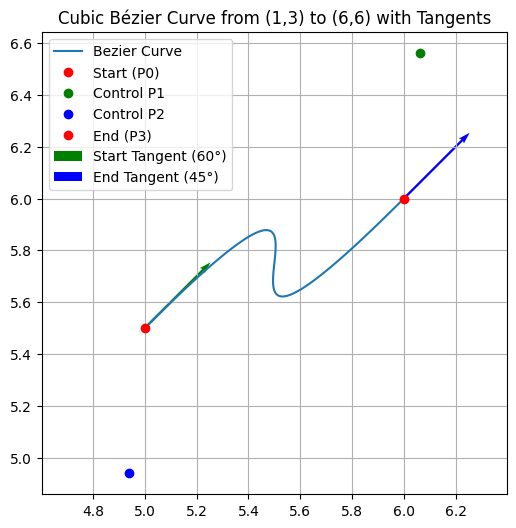

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define start and end points
P0 = np.array([5.0, 5.5])  # Start
P3 = np.array([6.0, 6.0])  # End

# Convert angles to radians
start_angle_deg = 45
end_angle_deg = 45
start_angle_rad = np.radians(start_angle_deg)
end_angle_rad = np.radians(end_angle_deg)

# Compute tangent direction vectors from angles
start_tangent = np.array([np.cos(start_angle_rad), np.sin(start_angle_rad)])
end_tangent = np.array([np.cos(end_angle_rad), np.sin(end_angle_rad)])

# Control point distance factor (tune for curvature)
d = 1.5

# Compute control points along tangent directions
P1 = P0 + d * start_tangent
P2 = P3 - d * end_tangent

# Bézier curve function
def bezier(t, P0, P1, P2, P3):
    return (1 - t)**3 * P0 + \
           3 * (1 - t)**2 * t * P1 + \
           3 * (1 - t) * t**2 * P2 + \
           t**3 * P3

# Generate curve
t_vals = np.linspace(0, 1, 100)
curve = np.array([bezier(t, P0, P1, P2, P3) for t in t_vals])

# Plotting
plt.figure(figsize=(6, 6))
plt.plot(curve[:, 0], curve[:, 1], label='Bezier Curve')
plt.plot(*P0, 'ro', label='Start (P0)')
plt.plot(*P1, 'go', label='Control P1')
plt.plot(*P2, 'bo', label='Control P2')
plt.plot(*P3, 'ro', label='End (P3)')

# Draw tangent vectors
plt.quiver(*P0, *start_tangent, scale=5, color='green', width=0.005, label='Start Tangent (60°)')
plt.quiver(*P3, *end_tangent, scale=5, color='blue', width=0.005, label='End Tangent (45°)')

plt.legend()
plt.axis('equal')
plt.grid(True)
plt.title("Cubic Bézier Curve from (1,3) to (6,6) with Tangents")
plt.show()


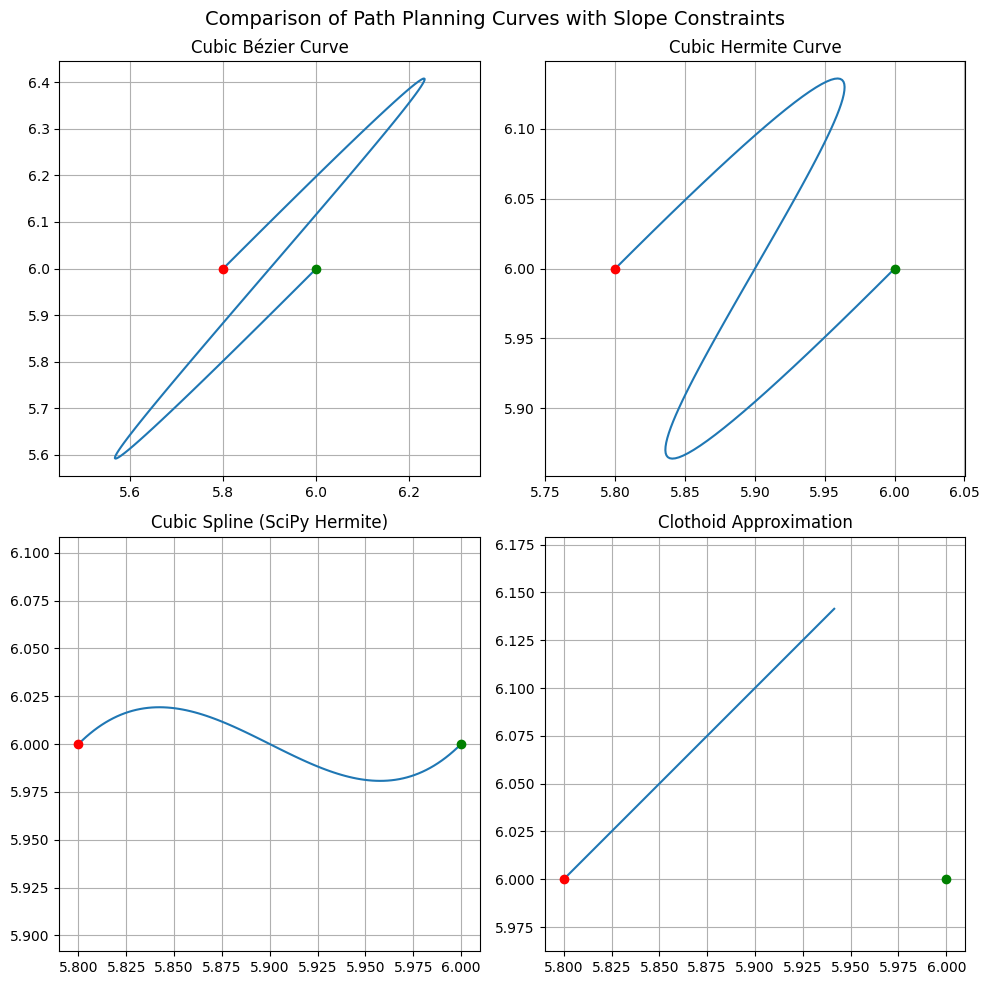

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicHermiteSpline

# ---- Common Setup ----
P0 = np.array([5.8, 6])
P3 = np.array([6.0, 6.0])
angle_start_deg = 45
angle_end_deg = 45
angle_start = np.radians(angle_start_deg)
angle_end = np.radians(angle_end_deg)

# Tangents
T0 = np.array([np.cos(angle_start), np.sin(angle_start)])
T1 = np.array([np.cos(angle_end), np.sin(angle_end)])

# Magnitude of tangents for Hermite and Bézier
tangent_mag = 2.0
T0_scaled = tangent_mag * T0
T1_scaled = tangent_mag * T1

t_vals = np.linspace(0, 1, 100)

# ---- 1. Cubic Bézier ----
P1 = P0 + T0_scaled
P2 = P3 - T1_scaled

def bezier(t, P0, P1, P2, P3):
    return (1 - t)**3 * P0 + 3*(1 - t)**2 * t * P1 + 3*(1 - t) * t**2 * P2 + t**3 * P3

bezier_curve = np.array([bezier(t, P0, P1, P2, P3) for t in t_vals])

# ---- 2. Hermite Curve ----
def hermite(t, P0, P1, T0, T1):
    h00 = 2*t**3 - 3*t**2 + 1
    h10 = t**3 - 2*t**2 + t
    h01 = -2*t**3 + 3*t**2
    h11 = t**3 - t**2
    return h00*P0 + h10*T0 + h01*P1 + h11*T1

hermite_curve = np.array([hermite(t, P0, P3, T0_scaled, T1_scaled) for t in t_vals])

# ---- 3. Cubic Spline (with Hermite-like interface via SciPy) ----
# We simulate a two-point spline using scipy.interpolate.CubicHermiteSpline
x_vals = [P0[0], P3[0]]
y_vals = [P0[1], P3[1]]
dy_dx = [T0[1]/T0[0], T1[1]/T1[0]]  # Derivatives w.r.t x

spline = CubicHermiteSpline(x_vals, y_vals, dy_dx)
x_spline = np.linspace(P0[0], P3[0], 100)
y_spline = spline(x_spline)

# ---- 4. Clothoid Approximation ----
# Simulate curvature transition by rotating the tangent direction gradually
clothoid = [P0]
pos = P0.copy()
num_pts = 100
step_size = np.linalg.norm(P3 - P0) / num_pts
angles = np.linspace(angle_start, angle_end, num_pts)

for angle in angles:
    direction = np.array([np.cos(angle), np.sin(angle)])
    pos = pos + step_size * direction
    clothoid.append(pos.copy())

clothoid = np.array(clothoid)

# ---- Plotting ----
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs = axs.flatten()

# Bézier
axs[0].plot(bezier_curve[:, 0], bezier_curve[:, 1])
axs[0].set_title("Cubic Bézier Curve")
axs[0].plot(*P0, 'ro')
axs[0].plot(*P3, 'go')
axs[0].axis('equal')
axs[0].grid()

# Hermite
axs[1].plot(hermite_curve[:, 0], hermite_curve[:, 1])
axs[1].set_title("Cubic Hermite Curve")
axs[1].plot(*P0, 'ro')
axs[1].plot(*P3, 'go')
axs[1].axis('equal')
axs[1].grid()

# Cubic Spline
axs[2].plot(x_spline, y_spline)
axs[2].set_title("Cubic Spline (SciPy Hermite)")
axs[2].plot(*P0, 'ro')
axs[2].plot(*P3, 'go')
axs[2].axis('equal')
axs[2].grid()

# Clothoid Approx
axs[3].plot(clothoid[:, 0], clothoid[:, 1])
axs[3].set_title("Clothoid Approximation")
axs[3].plot(*P0, 'ro')
axs[3].plot(*P3, 'go')
axs[3].axis('equal')
axs[3].grid()

plt.suptitle("Comparison of Path Planning Curves with Slope Constraints", fontsize=14)
plt.tight_layout()
plt.show()
